# 01: Exploratory data analysis

Stage 1 of [PLAN.md](../PLAN.md). The goal is to understand the data and the metric well enough to design the model.

1. Dataset overview: images, annotators, sites, time
2. Image properties: disk geometry, brightness, sharpness
3. Filament geometry: size, thickness, shape, location
4. How close filaments are to each other: do instances touch?
5. **Annotator agreement under the competition metric**, which gives the realistic ceiling
6. What-if experiments on annotations: outline width, connected-component instances
7. Filament contrast and how tight the outlines are
8. Time structure → cross-validation design

Heavy computations are cached under `outputs/eda/` (delete the files to recompute).
Findings are summarized in [notes/findings.md](../notes/findings.md).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2

from filament.paths import get_data_paths, get_output_dir
from filament.data.annotations import load_coco, annotation_table, annotator_image_table, image_table, SITE_NAMES
from filament.data.rle import rle_to_mask
from filament.analysis import eda

pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

paths = get_data_paths()
CACHE = get_output_dir("eda")
coco = load_coco(paths.annotations)
ann = annotation_table(coco)           # one row per filament annotation
ai = annotator_image_table(coco)       # one row per annotator-image
train_imgs = image_table([p.name for p in paths.train_images.glob("*.jpeg")]).assign(split="train")
test_imgs = image_table([p.name for p in paths.test_images.glob("*.jpeg")]).assign(split="test")
imgs = pd.concat([train_imgs, test_imgs], ignore_index=True)
imgs["year"] = imgs.time.dt.year

def cached(name, fn):
    path = CACHE / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False)
    return df

print(f"{len(train_imgs)} train images, {len(test_imgs)} test images, {len(ai)} annotator-images, {len(ann)} filaments")

707 train images, 180 test images, 1154 annotator-images, 8199 filaments


## 1. Dataset overview

Train images by number of independent annotators: {1: 411, 2: 145, 3: 151}
Filaments by category: {'Unidentifiable': 3074, 'Right': 2590, 'Left': 2535}
Filaments per annotator-image: median 7, mean 7.1, max 26
Annotator id = <group/batch 4 digits><copy 01-03>; images annotated by multiple people always share the first 4 digits.


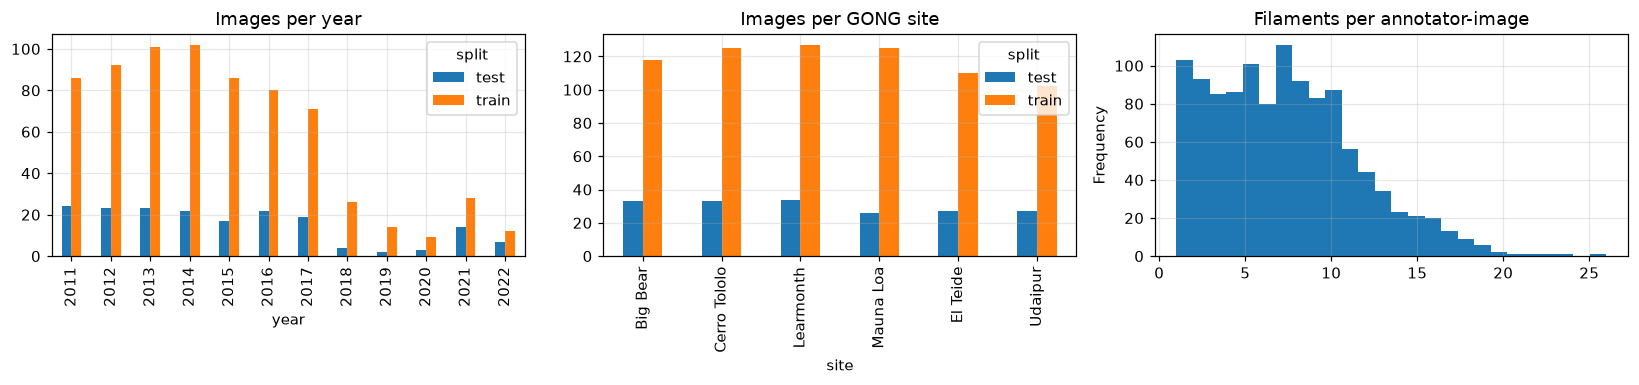

In [2]:
n_ann = ai.drop_duplicates("stem").n_annotators.value_counts().sort_index()
print("Train images by number of independent annotators:", n_ann.to_dict())
print("Filaments by category:", ann.category.value_counts().to_dict())
per_ai = ann.groupby("annotator_image").size()
print(f"Filaments per annotator-image: median {per_ai.median():.0f}, mean {per_ai.mean():.1f}, max {per_ai.max()}")
print("Annotator id = <group/batch 4 digits><copy 01-03>; images annotated by multiple people always share the first 4 digits.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pd.crosstab(imgs.year, imgs.split).plot.bar(ax=ax[0], title="Images per year")
pd.crosstab(imgs.site, imgs.split).rename(index=SITE_NAMES).plot.bar(ax=ax[1], title="Images per GONG site")
per_ai.plot.hist(bins=26, ax=ax[2], title="Filaments per annotator-image")
plt.tight_layout()

## 2. Image properties

Disk center and radius are estimated from the bright disk. The radial profile shows whether limb darkening remains.
NSO's JPEG conversion already applies a Fourier filter that removes large-scale intensity variations.

In [3]:
stats = cached("image_stats", lambda: eda.image_stats(
    sorted(paths.train_images.glob("*.jpeg")) + sorted(paths.test_images.glob("*.jpeg"))))
stats = stats.merge(imgs[["stem", "site", "split"]], on="stem")
print("Decoded JPEG array ndim (2 = single-channel grayscale):", stats.channels.value_counts().to_dict())
print(stats[["cx", "cy", "radius", "disk_mean", "disk_std", "sharpness", "frac_saturated"]].describe().round(2))

Decoded JPEG array ndim (2 = single-channel grayscale): {2: 887}
            cx       cy   radius  disk_mean  disk_std  sharpness  frac_saturated
count   887.00   887.00   887.00     887.00    887.00     887.00           887.0
mean   1021.64  1035.49   964.97     122.78     21.43     267.14             0.0
std      30.61    29.86    37.83       4.37      4.62     124.41             0.0
min     946.43   976.72   903.75     110.34     11.48      24.21             0.0
25%    1000.06  1019.18   937.62     120.07     18.45     221.51             0.0
50%    1022.94  1024.79   956.30     123.07     22.48     272.21             0.0
75%    1032.00  1061.02   998.75     126.29     24.23     360.83             0.0
max    1095.90  1099.31  1033.09     135.44     32.13     869.94             0.0


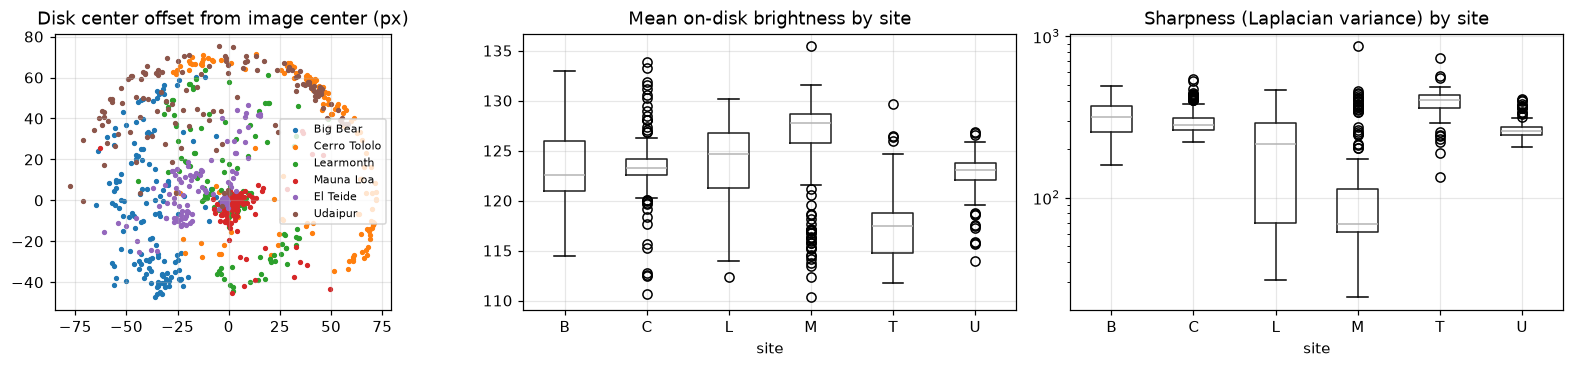

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for s, g in stats.groupby("site"):
    ax[0].scatter(g.cx - 1024, g.cy - 1024, s=6, label=SITE_NAMES[s])
ax[0].set(title="Disk center offset from image center (px)", aspect="equal"); ax[0].legend(fontsize=7)
stats.boxplot("disk_mean", by="site", ax=ax[1]); ax[1].set_title("Mean on-disk brightness by site")
stats.boxplot("sharpness", by="site", ax=ax[2]); ax[2].set_title("Sharpness (Laplacian variance) by site")
ax[2].set_yscale("log"); plt.suptitle(""); plt.tight_layout()

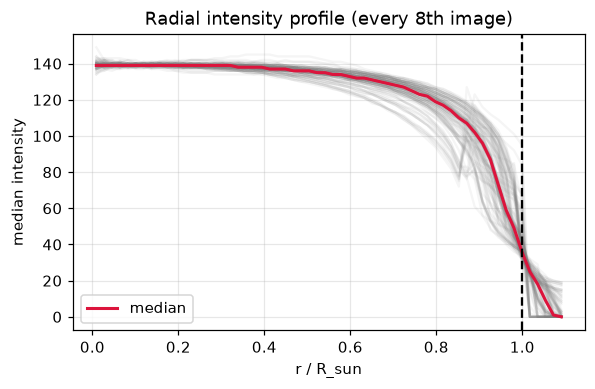

In [5]:
prof = cached("radial_profiles", lambda: None)  # computed by the background job; see eda.radial_profile
r = np.linspace(0, 1.1, 61)[:-1] + 1.1 / 120
vals = prof.iloc[:, 1:].to_numpy(float)
plt.figure(figsize=(6, 3.5))
plt.plot(r, vals.T, color="gray", alpha=0.08)
plt.plot(r, np.nanmedian(vals, 0), color="crimson", lw=2, label="median")
plt.axvline(1, ls="--", c="k"); plt.xlabel("r / R_sun"); plt.ylabel("median intensity")
plt.title("Radial intensity profile (every 8th image)"); plt.legend()

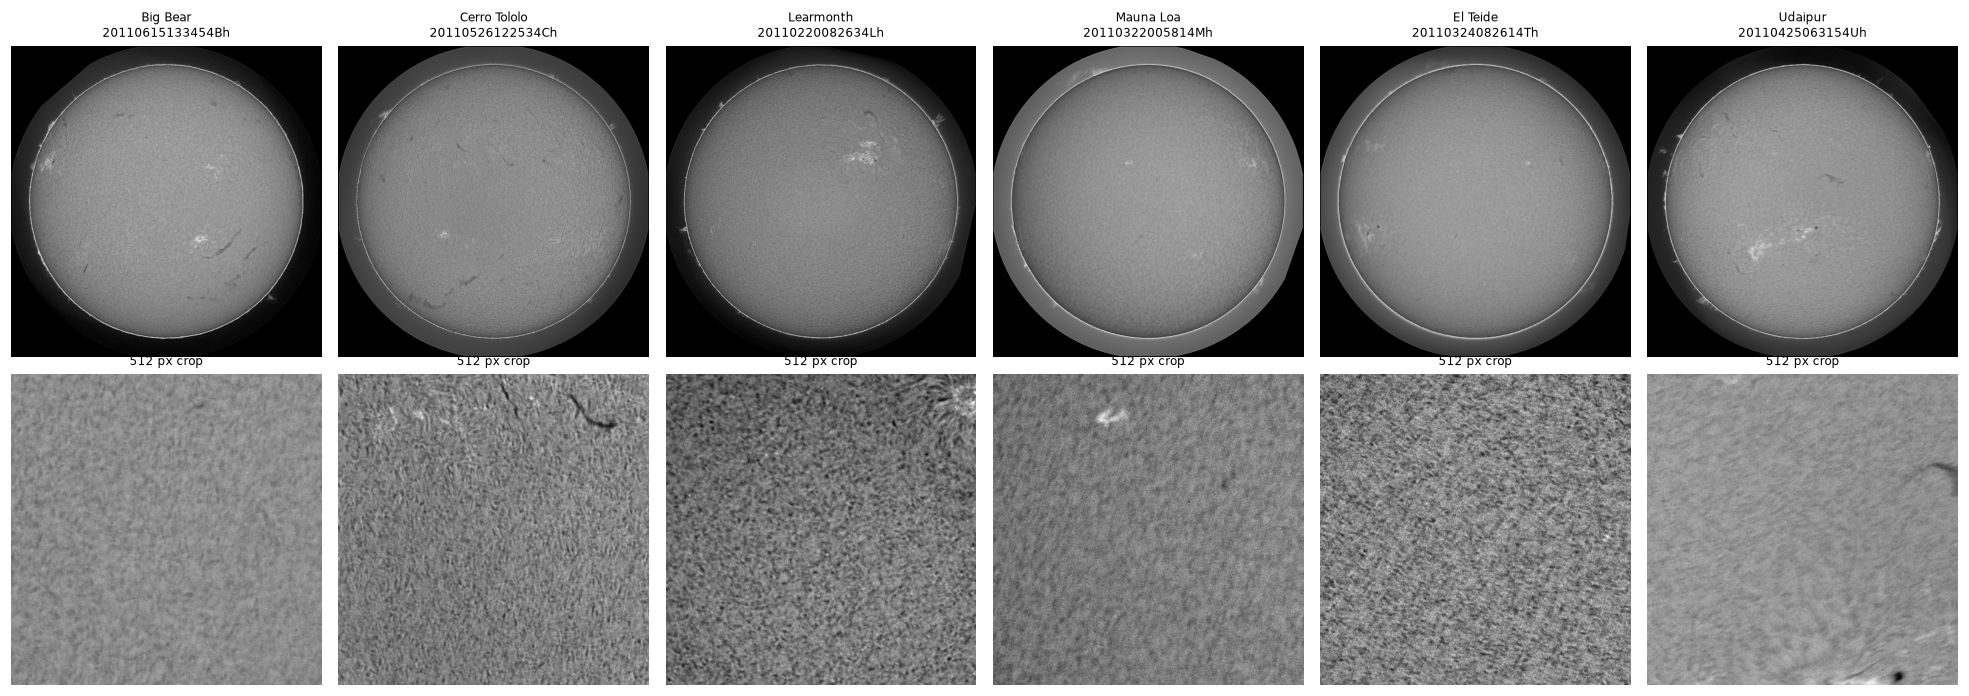

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6.4))
for col, site in enumerate(sorted(SITE_NAMES)):
    stem = train_imgs[train_imgs.site == site].stem.iloc[3]
    img = eda.read_gray(paths.train_images / f"{stem}.jpeg")
    axes[0, col].imshow(img, cmap="gray"); axes[0, col].set_title(f"{SITE_NAMES[site]}\n{stem}", fontsize=8)
    axes[1, col].imshow(img[700:1212, 700:1212], cmap="gray"); axes[1, col].set_title("512 px crop", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout()

## 3. Filament geometry

`mean_width ≈ 2·area/perimeter` approximates the typical thickness of thin shapes; `max_half_width` is the radius of the
thickest part.

In [7]:
shape = cached("shape_stats", lambda: eda.shape_stats(ann).reset_index()).set_index("idx")
fil = ann.drop(columns=["rle", "spine"]).join(shape)
geo = stats.set_index("stem")[["cx", "cy", "radius"]].add_prefix("disk_")
fil = fil.join(geo, on="stem")
fil["r_norm"] = np.hypot(fil.cx - fil.disk_cx, fil.cy - fil.disk_cy) / fil.disk_radius
print(fil.groupby("category")[["mask_area", "length", "mean_width", "max_half_width", "elongation", "solidity"]]
      .median().round(2))
print("Filaments with >1 connected piece:", (fil.n_components > 1).mean().round(4))
print("Filament centers beyond the limb (r>1):", (fil.r_norm > 1).mean().round(4))

                mask_area  length  mean_width  max_half_width  elongation  solidity
category                                                                           
Left               1438.0  124.14        7.85            7.80        3.80      0.51
Right              1524.0  130.15        7.97            7.99        3.84      0.50
Unidentifiable      868.5   73.76        9.09            7.80        3.40      0.74
Filaments with >1 connected piece: 0.0037
Filament centers beyond the limb (r>1): 0.0


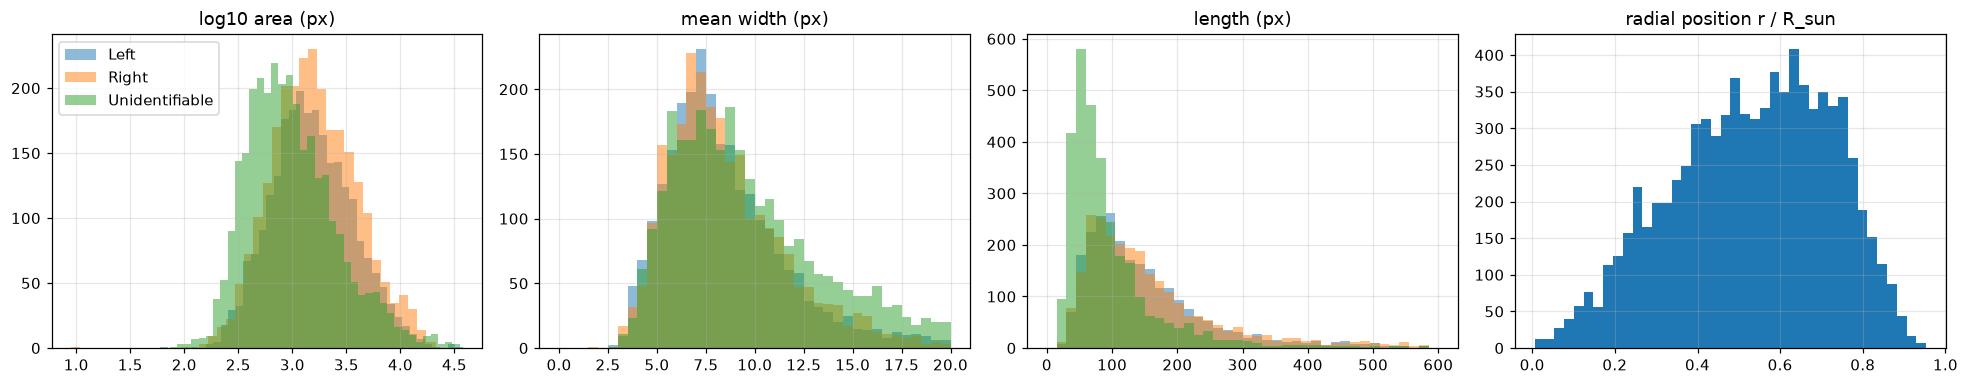

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for cat, g in fil.groupby("category"):
    ax[0].hist(np.log10(g.mask_area), bins=40, alpha=0.5, label=cat)
    ax[1].hist(g.mean_width, bins=np.linspace(0, 20, 41), alpha=0.5, label=cat)
    ax[2].hist(g.length, bins=np.linspace(0, 600, 41), alpha=0.5, label=cat)
ax[0].set_title("log10 area (px)"); ax[1].set_title("mean width (px)"); ax[2].set_title("length (px)")
ax[0].legend()
ax[3].hist(fil.r_norm, bins=40); ax[3].set_title("radial position r / R_sun")
plt.tight_layout()

## 4. Do filaments touch?

If instances from one annotator never overlap and rarely come within a few pixels of each other, then
*semantic segmentation + connected components* recovers the instances, and no dedicated instance head is needed.

In [9]:
spacing = cached("instance_spacing", lambda: eda.instance_spacing(ann))
n_pairs_total = sum(n * (n - 1) // 2 for n in ann.groupby("annotator_image").size())
print(f"{n_pairs_total} filament pairs within annotator-images, {len(spacing)} within 40 px bbox distance")
print("Pairs with pixel overlap:", int((spacing.overlap_px > 0).sum()))
for g in [0, 1, 2, 3, 5, 10, 20, 40]:
    n = int((spacing.gap <= g).sum())
    print(f"  gap <= {g:>2} px: {n:5d} pairs  ({n / len(ann) * 100:.1f} per 100 filaments)")

36064 filament pairs within annotator-images, 1237 within 40 px bbox distance
Pairs with pixel overlap: 5
  gap <=  0 px:     5 pairs  (0.1 per 100 filaments)
  gap <=  1 px:     7 pairs  (0.1 per 100 filaments)
  gap <=  2 px:    12 pairs  (0.1 per 100 filaments)
  gap <=  3 px:    23 pairs  (0.3 per 100 filaments)
  gap <=  5 px:    46 pairs  (0.6 per 100 filaments)
  gap <= 10 px:   117 pairs  (1.4 per 100 filaments)
  gap <= 20 px:   243 pairs  (3.0 per 100 filaments)
  gap <= 40 px:   580 pairs  (7.1 per 100 filaments)


## 5. Annotator agreement: the realistic ceiling

296 training images have 2 or 3 independent annotations. Each annotator in turn is treated as "the submission" and
scored against the others with the competition's PQ. This is exactly how the official metric treats a
multi-annotated test image, so it estimates what a model that is "as good as a single human" would score.

In [10]:
agree = eda.pairwise_agreement(ann, ai)
print(agree)
pairs = agree.per_image()
print("PQ per annotator pair: quantiles", pairs.pq.quantile([.1, .25, .5, .75, .9]).round(3).to_dict())
print(eda.degree_summary(agree).head(6).T)

PQResult(pq=0.3399, sq=0.6337, rq=0.5364, tp=4292, fp=3709, fn=3709, n_images=1196)
PQ per annotator pair: quantiles {0.1: 0.13, 0.25: 0.225, 0.5: 0.342, 0.75: 0.452, 0.9: 0.55}
                                 0     1    2   3  4
GT filament overlaps k preds  1420  6326  225  26  2
pred filament overlaps k GTs  1420  6326  225  26  2


Outcome of each filament when compared with another annotator:
{'match': 0.536, 'low_iou': 0.195, 'missing': 0.178, 'merged': 0.063, 'split': 0.029}


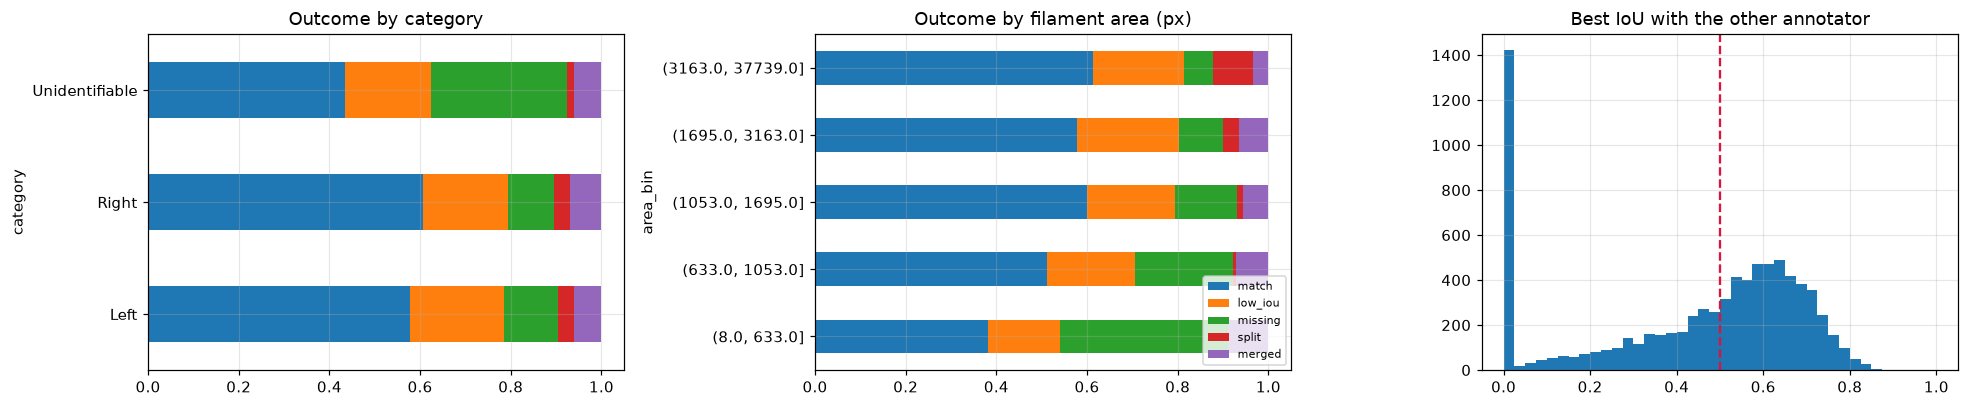

In [11]:
pf = eda.per_filament_match(ann, ai)
print("Outcome of each filament when compared with another annotator:")
print(pf.outcome.value_counts(normalize=True).round(3).to_dict())
pf["area_bin"] = pd.qcut(pf.area, 5, precision=0)
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
order = ["match", "low_iou", "missing", "split", "merged"]
pd.crosstab(pf.category, pf.outcome, normalize="index")[order].plot.barh(stacked=True, ax=ax[0], legend=False)
ax[0].set_title("Outcome by category")
pd.crosstab(pf.area_bin, pf.outcome, normalize="index")[order].plot.barh(stacked=True, ax=ax[1])
ax[1].set_title("Outcome by filament area (px)"); ax[1].legend(fontsize=7, loc="lower right")
ax[2].hist(pf.best_iou, bins=np.linspace(0, 1, 41)); ax[2].axvline(0.5, c="crimson", ls="--")
ax[2].set_title("Best IoU with the other annotator")
plt.tight_layout()

In [12]:
udice = eda.union_dice(ann, ai)
print(f"Pixel-level Dice between annotators' union masks (ignoring instances): median {udice.dice.median():.3f}, "
      f"mean {udice.dice.mean():.3f}")

Pixel-level Dice between annotators' union masks (ignoring instances): median 0.641, mean 0.614


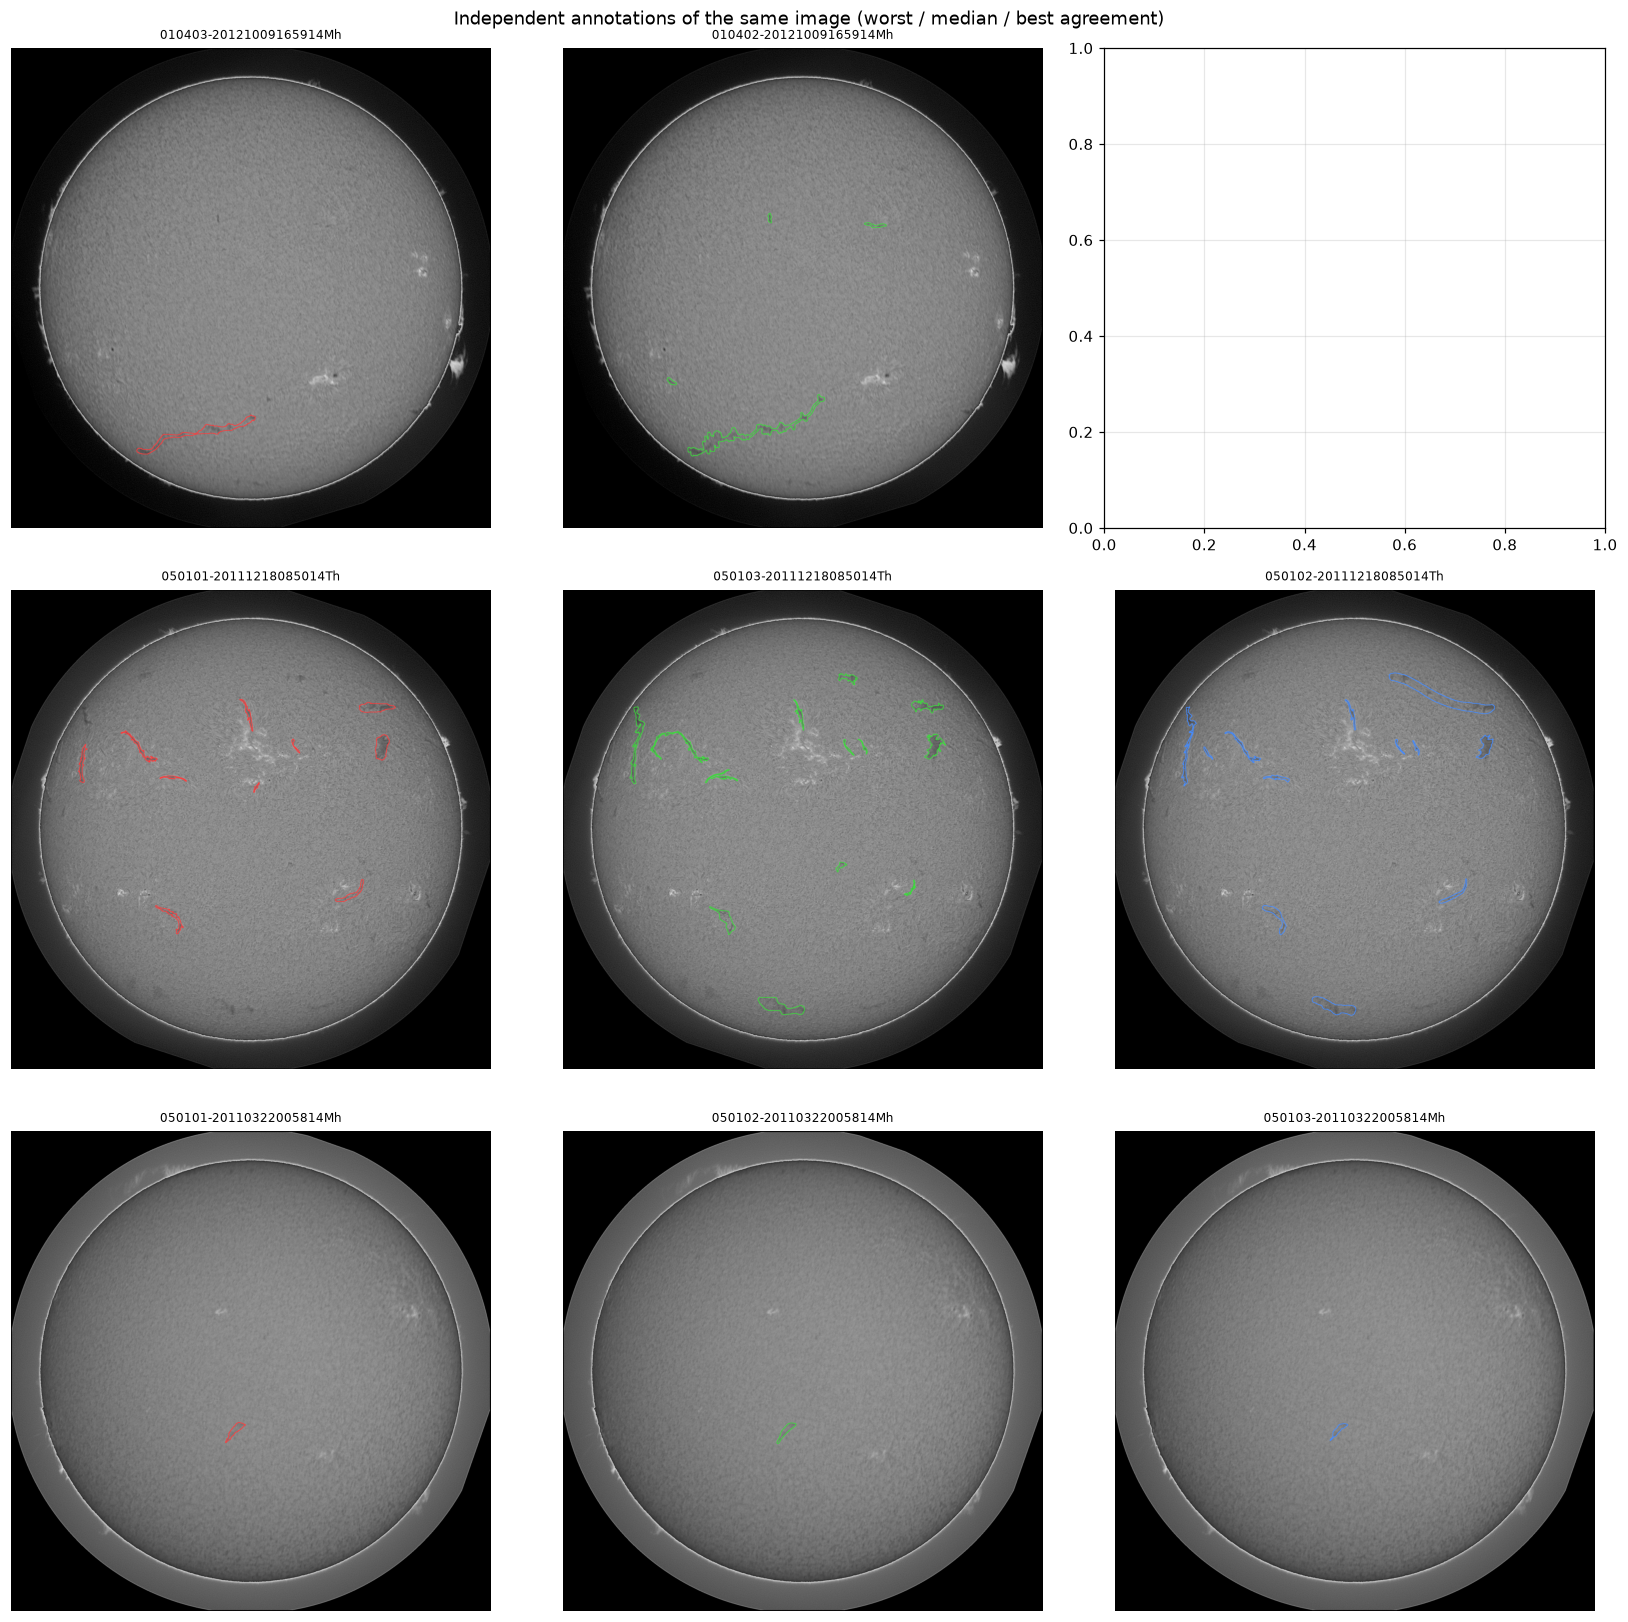

In [13]:
def show_annotators(stem, crop=None, ax_row=None):
    img = eda.read_gray(paths.train_images / f"{stem}.jpeg")
    ids = ai[ai.stem == stem].annotator_image.tolist()
    colors = [(255, 60, 60), (60, 220, 60), (70, 140, 255)]
    for k, (aid, color) in enumerate(zip(ids, colors)):
        vis = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        for rle in ann[ann.annotator_image == aid].rle:
            m = rle_to_mask(rle).astype(np.uint8)
            cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            cv2.drawContours(vis, cs, -1, color, 2)
        if crop:
            y0, y1, x0, x1 = crop; vis = vis[y0:y1, x0:x1]
        ax_row[k].imshow(vis); ax_row[k].set_title(aid, fontsize=8); ax_row[k].axis("off")

worst = pairs.assign(stem=pairs.key.str.split("|").str[0].str.split("-").str[1]).groupby("stem").pq.mean()
examples = [worst.idxmin(), worst.sub(worst.median()).abs().idxmin(), worst.idxmax()]
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for row, stem in enumerate(examples):
    show_annotators(stem, ax_row=axes[row])
    axes[row, 0].set_ylabel(f"{stem}  mean PQ={worst[stem]:.2f}")
plt.suptitle("Independent annotations of the same image (worst / median / best agreement)"); plt.tight_layout()

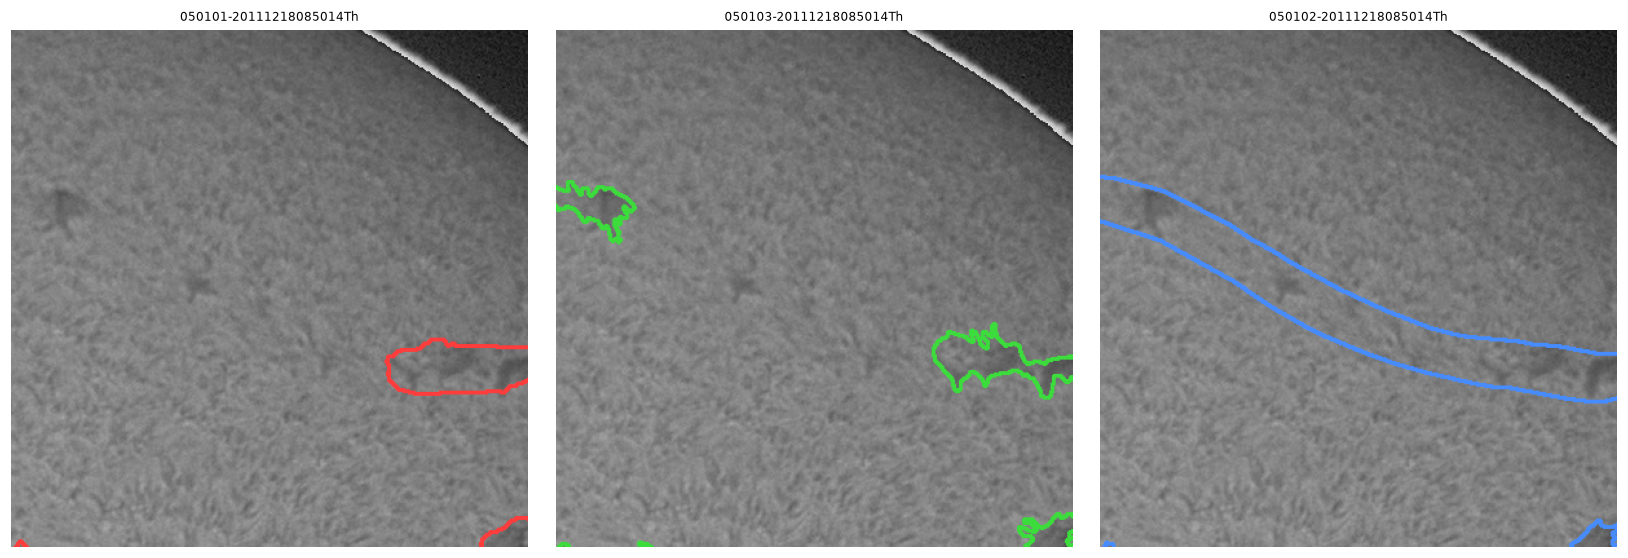

In [14]:
# Zoom on the largest filaments of the median-agreement image, where boundary differences are visible
stem = examples[1]
b = ann[(ann.stem == stem)].sort_values("area").iloc[-1]
cy, cx = int(b.bbox_y + b.bbox_h / 2), int(b.bbox_x + b.bbox_w / 2)
crop = (max(cy - 200, 0), cy + 200, max(cx - 200, 0), cx + 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 5)); show_annotators(stem, crop, axes); plt.tight_layout()

## 6. What-if experiments on the annotations

Annotator B's masks are modified and then scored against annotator A:
* **Outline width:** dilate or erode B's masks by k px. Does a slightly wider or narrower outline agree better with
  other people?
* **Connected components:** discard B's instance IDs, take the union mask, and split it into connected components
  (optionally linking pieces within d px). If PQ barely changes, *semantic segmentation + connected components* loses
  nothing.

In [15]:
def whatif():
    rows = []
    for k in [-2, -1, 1, 2, 3]:
        r = eda.transformed_agreement(ann, ai, lambda ms, k=k: eda.morph(ms, k))
        rows.append({"experiment": f"morph {k:+d}px", "pq": r.pq, "sq": r.sq, "rq": r.rq})
    for d in [0, 3, 6, 10, 20]:
        r = eda.transformed_agreement(ann, ai, lambda ms, d=d: eda.reinstance_by_components(ms, d))
        rows.append({"experiment": f"CC link {d}px", "pq": r.pq, "sq": r.sq, "rq": r.rq})
    return pd.DataFrame(rows)

base = pd.DataFrame([{"experiment": "original", "pq": agree.pq, "sq": agree.sq, "rq": agree.rq}])
print(pd.concat([base, cached("whatif", whatif)]).round(4).to_string(index=False))

  experiment     pq     sq     rq
    original 0.3399 0.6337 0.5364
  morph -2px 0.1462 0.5994 0.2439
  morph -1px 0.2803 0.6163 0.4548
  morph +1px 0.3381 0.6369 0.5308
  morph +2px 0.2891 0.6196 0.4666
  morph +3px 0.2336 0.6059 0.3856
 CC link 0px 0.3391 0.6336 0.5352
 CC link 3px 0.3389 0.6329 0.5355
 CC link 6px 0.3370 0.6327 0.5326
CC link 10px 0.3345 0.6327 0.5287
CC link 20px 0.3257 0.6323 0.5152


## 7. Filament contrast and outline tightness

For a sample of annotator-images: filament intensity vs. a 15 px ring around it.
`frac_darker_than_ring` is the share of mask pixels darker than the local background (1.0 = tight outline).
`frac_ring_dark` is the share of the ring that is as dark as the filament core (high = dark pixels left out).

                inside_median  ring_median  contrast  frac_darker_than_ring  frac_ring_dark
category                                                                                   
Left                    119.0        136.5     0.119                  0.914           0.027
Right                   119.0        137.0     0.123                  0.925           0.021
Unidentifiable          120.0        135.0     0.103                  0.904           0.036


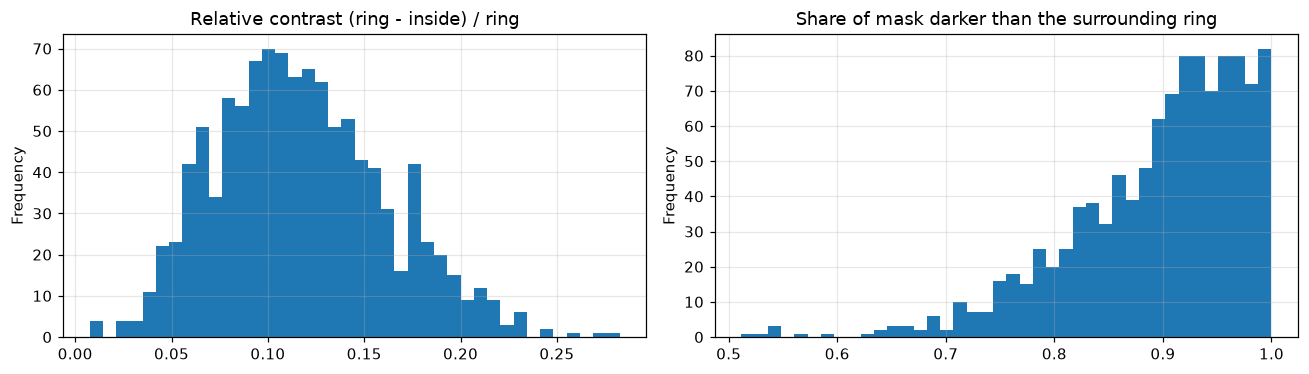

In [16]:
def contrast_sample(n=150, seed=0):
    rows = []
    for aid in ai.sample(n, random_state=seed).annotator_image:
        g = ann[ann.annotator_image == aid]
        img = eda.read_gray(paths.train_images / f"{aid.split('-', 1)[1]}.jpeg")
        masks = [rle_to_mask(r) for r in g.rle]
        for (idx, cat), row in zip(g.category.items(), eda.filament_contrast(img, masks)):
            rows.append({"idx": idx, "category": cat, **row})
    return pd.DataFrame(rows)

con = cached("contrast", contrast_sample)
print(con.groupby("category")[["inside_median", "ring_median", "contrast", "frac_darker_than_ring", "frac_ring_dark"]]
      .median().round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
con.contrast.plot.hist(bins=40, ax=ax[0], title="Relative contrast (ring - inside) / ring")
con.frac_darker_than_ring.plot.hist(bins=40, ax=ax[1], title="Share of mask darker than the surrounding ring")
plt.tight_layout()

## 8. Time structure → cross-validation design

Filaments live for days, so images taken hours apart show the same filaments. How close is each test image to its
nearest training image, compared with training images among themselves?

test  -> nearest train (h):

 [  4.4  15.9  36.7  72.  141.3]  share < 24h: 0.35
train -> nearest train (h): [  8.1  21.5  36.4  66.2 119.9]  share < 24h: 0.31


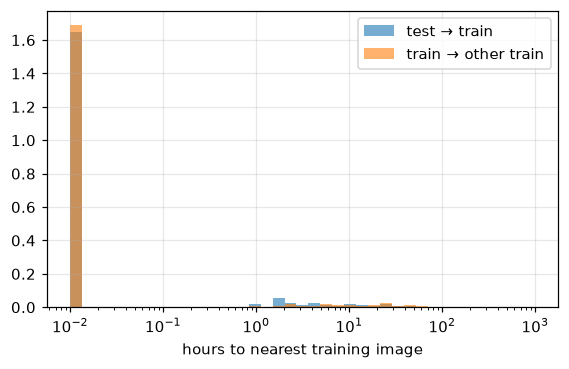

In [17]:
def nearest_hours(times, ref, exclude_self=False):
    ref = np.sort(ref.astype("datetime64[s]").astype(np.int64))
    out = []
    for t in times.astype("datetime64[s]").astype(np.int64):
        d = np.abs(ref - t)
        if exclude_self:
            d = d[d > 0]
        out.append(d.min() / 3600)
    return np.array(out)

h_test = nearest_hours(test_imgs.time.values, train_imgs.time.values)
h_train = nearest_hours(train_imgs.time.values, train_imgs.time.values, exclude_self=True)
q = [0.1, 0.25, 0.5, 0.75, 0.9]
print("test  -> nearest train (h):", np.quantile(h_test, q).round(1), f" share < 24h: {(h_test < 24).mean():.2f}")
print("train -> nearest train (h):", np.quantile(h_train, q).round(1), f" share < 24h: {(h_train < 24).mean():.2f}")
bins = np.logspace(-2, 3, 40)
plt.figure(figsize=(6, 3.5))
plt.hist(h_test, bins, alpha=0.6, density=True, label="test → train")
plt.hist(h_train, bins, alpha=0.6, density=True, label="train → other train")
plt.xscale("log"); plt.xlabel("hours to nearest training image"); plt.legend()

## Summary

See [notes/findings.md](../notes/findings.md) for the written conclusions and their consequences for the model design.